Assignment: Comparative Study — Multi-Class Wine Quality Classification
1. Problem Statement
The objective of this project is to build machine learning classification models that predict wine quality based on its chemical properties.

We will use two datasets: red wine and white wine. Each row represents a wine sample, and the dataset contains measurements such as acidity, residual sugar, density, pH, sulphates, and alcohol.

The target variable is quality, which represents the wine's quality score.

In this assignment, each unique quality score will be treated as a separate class. Therefore, this is a multi-class classification problem.

We will train two machine learning models:
1. Logistic Regression
2. Random Forest Classifier
We will evaluate both models using accuracy, confusion matrices, classification reports, and macro F1-score.

Finally, we will compare the results to determine which dataset is easier to predict, which model performs better, and which quality scores are the most difficult to classify.
Understand what you just wrote
Let's understand the important terms before coding.
Term	Simple explanation
Dataset	A collection of data arranged in rows and columns
Feature	An input variable used to make a prediction
Target	The value we want the model to predict
Classification	Predicting a category or class
Multi-class classification	Predicting one of more than two possible classes
Model	An algorithm trained to make predictions
Accuracy	The proportion of predictions that are correct


Example: Suppose a wine sample has certain alcohol, acidity, and pH values. Our model will use those measurements to predict its quality score.

That is the basic idea of this project!

In [1]:
import pandas as pd

In [2]:
# Load the red wine dataset
red_wine = pd.read_csv("winequality-red.csv", sep=";")

# Load the white wine dataset
white_wine = pd.read_csv("winequality-white.csv", sep=";")

print("Both datasets loaded successfully!")

Both datasets loaded successfully!


In [3]:
print("Red Wine Dataset Shape:", red_wine.shape)

print("White Wine Dataset Shape:", white_wine.shape)

Red Wine Dataset Shape: (1599, 12)
White Wine Dataset Shape: (4898, 12)


In [4]:
print("First 5 rows of Red Wine Dataset:")
display(red_wine.head())

print("First 5 rows of White Wine Dataset:")
display(white_wine.head())

First 5 rows of Red Wine Dataset:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


First 5 rows of White Wine Dataset:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [5]:
print("Red Wine Columns:")
print(red_wine.columns.tolist())

print("\nWhite Wine Columns:")
print(white_wine.columns.tolist())

Red Wine Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

White Wine Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [6]:
print("Does red wine contain the quality column?",
      "quality" in red_wine.columns)

print("Does white wine contain the quality column?",
      "quality" in white_wine.columns)

Does red wine contain the quality column? True
Does white wine contain the quality column? True


In [7]:
# Check missing values in the red wine dataset
print("Missing Values - Red Wine")
print(red_wine.isnull().sum())

# Check missing values in the white wine dataset
print("\nMissing Values - White Wine")
print(white_wine.isnull().sum())

Missing Values - Red Wine
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Missing Values - White Wine
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [8]:
# Count duplicate rows in the red wine dataset
print("Duplicate Rows - Red Wine:", red_wine.duplicated().sum())

# Count duplicate rows in the white wine dataset
print("Duplicate Rows - White Wine:", white_wine.duplicated().sum())

Duplicate Rows - Red Wine: 240
Duplicate Rows - White Wine: 937


In [9]:
# Quality score counts for red wine
print("Quality Counts - Red Wine")
print(red_wine["quality"].value_counts().sort_index())

# Quality score counts for white wine
print("\nQuality Counts - White Wine")
print(white_wine["quality"].value_counts().sort_index())

Quality Counts - Red Wine
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Quality Counts - White Wine
quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64


In [10]:
# Quality score percentages for red wine
red_quality_percent = (
    red_wine["quality"].value_counts(normalize=True).sort_index() * 100
)

print("Quality Percentages - Red Wine")
print(red_quality_percent.round(2))

# Quality score percentages for white wine
white_quality_percent = (
    white_wine["quality"].value_counts(normalize=True).sort_index() * 100
)

print("\nQuality Percentages - White Wine")
print(white_quality_percent.round(2))

Quality Percentages - Red Wine
quality
3     0.63
4     3.31
5    42.59
6    39.90
7    12.45
8     1.13
Name: proportion, dtype: float64

Quality Percentages - White Wine
quality
3     0.41
4     3.33
5    29.75
6    44.88
7    17.97
8     3.57
9     0.10
Name: proportion, dtype: float64


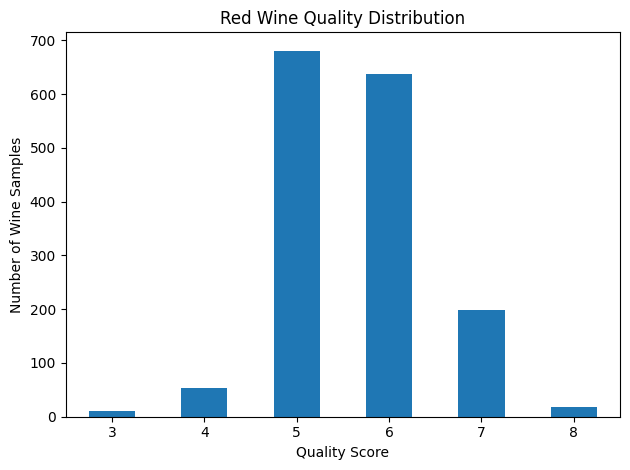

In [12]:
import matplotlib.pyplot as plt

# Plot the red wine quality distribution
red_wine["quality"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Red Wine Quality Distribution")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wine Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

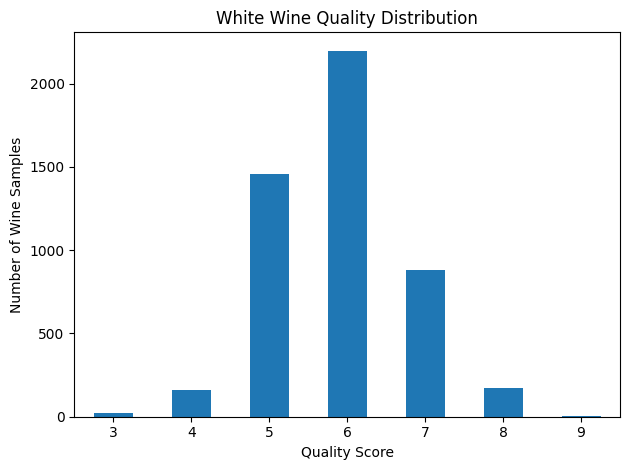

In [13]:
# Plot the white wine quality distribution
white_wine["quality"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("White Wine Quality Distribution")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wine Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Task 2 — Data Quality and Class Distribution Observations

Both datasets contain no missing values. The red wine dataset contains 240 duplicate rows, while the white wine dataset contains 937 duplicate rows. Duplicate rows were identified but not removed.

The red wine dataset is concentrated around quality scores 5 and 6, which together represent approximately 82.49% of the samples. In the white wine dataset, quality scores 5 and 6 represent approximately 74.63% of the samples.

The red wine dataset has relatively few samples with quality scores 3 and 8. The white wine dataset has relatively few samples with quality scores 3 and 9, especially quality 9, which has only 5 samples.

These distributions show that the quality classes are imbalanced. Models may predict common quality scores more successfully than rare scores because the training data contains fewer examples of the rare classes.

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
# Separate input features and target for red wine
X_red = red_wine.drop("quality", axis=1)
y_red = red_wine["quality"]

print("Red Wine Features Shape:", X_red.shape)
print("Red Wine Target Shape:", y_red.shape)

Red Wine Features Shape: (1599, 11)
Red Wine Target Shape: (1599,)


In [16]:
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_red,
    y_red,
    test_size=0.2,
    random_state=42,
    stratify=y_red
)

print("Red Wine Training Features:", X_train_red.shape)
print("Red Wine Testing Features:", X_test_red.shape)
print("Red Wine Training Target:", y_train_red.shape)
print("Red Wine Testing Target:", y_test_red.shape)

Red Wine Training Features: (1279, 11)
Red Wine Testing Features: (320, 11)
Red Wine Training Target: (1279,)
Red Wine Testing Target: (320,)


In [17]:
# Separate input features and target for white wine
X_white = white_wine.drop("quality", axis=1)
y_white = white_wine["quality"]

print("White Wine Features Shape:", X_white.shape)
print("White Wine Target Shape:", y_white.shape)

White Wine Features Shape: (4898, 11)
White Wine Target Shape: (4898,)


In [18]:
X_train_white, X_test_white, y_train_white, y_test_white = train_test_split(
    X_white,
    y_white,
    test_size=0.2,
    random_state=42,
    stratify=y_white
)

print("White Wine Training Features:", X_train_white.shape)
print("White Wine Testing Features:", X_test_white.shape)
print("White Wine Training Target:", y_train_white.shape)
print("White Wine Testing Target:", y_test_white.shape)

White Wine Training Features: (3918, 11)
White Wine Testing Features: (980, 11)
White Wine Training Target: (3918,)
White Wine Testing Target: (980,)


Observation:

Both datasets were separated into input features (X) and the target variable (y). The quality column was selected as the target, while the remaining 11 columns were used as input features. The datasets were split into 80% training data and 20% testing data using random_state=42 and stratify=y. Stratification helps maintain similar quality-class proportions in the training and testing sets.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score
)

In [20]:
# Create the Logistic Regression pipeline
logistic_red = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

# Train the model using red wine training data
logistic_red.fit(X_train_red, y_train_red)

# Predict quality scores for red wine test data
y_pred_logistic_red = logistic_red.predict(X_test_red)

print("Logistic Regression - Red Wine")
print("Model trained and predictions completed!")

Logistic Regression - Red Wine
Model trained and predictions completed!


In [21]:
# Calculate evaluation metrics for red wine
accuracy_red_logistic = accuracy_score(
    y_test_red,
    y_pred_logistic_red
)

macro_f1_red_logistic = f1_score(
    y_test_red,
    y_pred_logistic_red,
    average="macro",
    zero_division=0
)

print("Logistic Regression - Red Wine")
print("Accuracy:", round(accuracy_red_logistic, 4))
print("Macro F1-score:", round(macro_f1_red_logistic, 4))

Logistic Regression - Red Wine
Accuracy: 0.5906
Macro F1-score: 0.2776


In [22]:
# Confusion matrix for red wine Logistic Regression
cm_red_logistic = confusion_matrix(
    y_test_red,
    y_pred_logistic_red
)

print("Confusion Matrix - Red Wine Logistic Regression")
print(cm_red_logistic)

Confusion Matrix - Red Wine Logistic Regression
[[ 0  0  1  1  0  0]
 [ 0  0 10  1  0  0]
 [ 0  0 99 36  1  0]
 [ 0  0 47 78  3  0]
 [ 0  0  2 26 12  0]
 [ 0  0  0  2  1  0]]


In [23]:
print("Classification Report - Red Wine Logistic Regression")

print(
    classification_report(
        y_test_red,
        y_pred_logistic_red,
        zero_division=0
    )
)

Classification Report - Red Wine Logistic Regression
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.62      0.73      0.67       136
           6       0.54      0.61      0.57       128
           7       0.71      0.30      0.42        40
           8       0.00      0.00      0.00         3

    accuracy                           0.59       320
   macro avg       0.31      0.27      0.28       320
weighted avg       0.57      0.59      0.57       320



In [24]:
# Create the Logistic Regression pipeline for white wine
logistic_white = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

# Train the model
logistic_white.fit(X_train_white, y_train_white)

# Predict quality scores
y_pred_logistic_white = logistic_white.predict(X_test_white)

print("Logistic Regression - White Wine")
print("Model trained and predictions completed!")

Logistic Regression - White Wine
Model trained and predictions completed!


In [25]:
# Calculate evaluation metrics for white wine
accuracy_white_logistic = accuracy_score(
    y_test_white,
    y_pred_logistic_white
)

macro_f1_white_logistic = f1_score(
    y_test_white,
    y_pred_logistic_white,
    average="macro",
    zero_division=0
)

print("Logistic Regression - White Wine")
print("Accuracy:", round(accuracy_white_logistic, 4))
print("Macro F1-score:", round(macro_f1_white_logistic, 4))

Logistic Regression - White Wine
Accuracy: 0.549
Macro F1-score: 0.2367


In [26]:
cm_white_logistic = confusion_matrix(
    y_test_white,
    y_pred_logistic_white
)

print("Confusion Matrix - White Wine Logistic Regression")
print(cm_white_logistic)

Confusion Matrix - White Wine Logistic Regression
[[  0   0   1   3   0   0   0]
 [  0   2  19  12   0   0   0]
 [  0   1 153 134   3   0   0]
 [  0   1  78 335  26   0   0]
 [  0   0   6 122  48   0   0]
 [  0   0   3  25   7   0   0]
 [  0   0   0   0   1   0   0]]


In [27]:
print("Classification Report - White Wine Logistic Regression")

print(
    classification_report(
        y_test_white,
        y_pred_logistic_white,
        zero_division=0
    )
)

Classification Report - White Wine Logistic Regression
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.50      0.06      0.11        33
           5       0.59      0.53      0.56       291
           6       0.53      0.76      0.63       440
           7       0.56      0.27      0.37       176
           8       0.00      0.00      0.00        35
           9       0.00      0.00      0.00         1

    accuracy                           0.55       980
   macro avg       0.31      0.23      0.24       980
weighted avg       0.53      0.55      0.52       980



Task 4 — Interpretation and Comparison
1. Which dataset performed better for Logistic Regression?

The red wine dataset performed better than the white wine dataset. Red wine achieved an accuracy of 59.06% and a macro F1-score of 0.2776, while white wine achieved an accuracy of 54.90% and a macro F1-score of 0.2367. Therefore, red wine performed better according to both evaluation metrics. However, the low macro F1-scores indicate that the model struggles to classify some quality classes.

2. Which quality classes were hardest to predict?

For red wine, quality classes 3, 4, and 8 had zero recall, while quality 7 had a recall of 0.30. For white wine, quality classes 3, 8, and 9 had zero recall, and quality 4 had a recall of only 0.06. These results suggest that rare classes are difficult for Logistic Regression to identify. The limited number of samples in these classes may contribute to the poor performance.

In [29]:
from sklearn.ensemble import RandomForestClassifier

In [30]:
# Create the Random Forest model for red wine
rf_red = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

# Train the model
rf_red.fit(X_train_red, y_train_red)

# Predict quality scores
y_pred_rf_red = rf_red.predict(X_test_red)

print("Random Forest - Red Wine")
print("Model trained and predictions completed!")

Random Forest - Red Wine
Model trained and predictions completed!


In [31]:
# Calculate accuracy
accuracy_red_rf = accuracy_score(
    y_test_red,
    y_pred_rf_red
)

# Calculate macro F1-score
macro_f1_red_rf = f1_score(
    y_test_red,
    y_pred_rf_red,
    average="macro",
    zero_division=0
)

print("Random Forest - Red Wine")
print("Accuracy:", round(accuracy_red_rf, 4))
print("Macro F1-score:", round(macro_f1_red_rf, 4))

Random Forest - Red Wine
Accuracy: 0.6813
Macro F1-score: 0.4094


In [32]:
cm_red_rf = confusion_matrix(
    y_test_red,
    y_pred_rf_red
)

print("Confusion Matrix - Red Wine Random Forest")
print(cm_red_rf)

Confusion Matrix - Red Wine Random Forest
[[  0   1   1   0   0   0]
 [  0   0   8   3   0   0]
 [  0   0 103  32   1   0]
 [  0   0  32  92   4   0]
 [  0   0   2  15  22   1]
 [  0   0   0   1   1   1]]


In [33]:
print("Classification Report - Red Wine Random Forest")

print(
    classification_report(
        y_test_red,
        y_pred_rf_red,
        zero_division=0
    )
)

Classification Report - Red Wine Random Forest
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.71      0.76      0.73       136
           6       0.64      0.72      0.68       128
           7       0.79      0.55      0.65        40
           8       0.50      0.33      0.40         3

    accuracy                           0.68       320
   macro avg       0.44      0.39      0.41       320
weighted avg       0.66      0.68      0.67       320



In [34]:
# Create the Random Forest model for white wine
rf_white = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

# Train the model
rf_white.fit(X_train_white, y_train_white)

# Predict quality scores
y_pred_rf_white = rf_white.predict(X_test_white)

print("Random Forest - White Wine")
print("Model trained and predictions completed!")

Random Forest - White Wine
Model trained and predictions completed!


In [35]:
accuracy_white_rf = accuracy_score(
    y_test_white,
    y_pred_rf_white
)

macro_f1_white_rf = f1_score(
    y_test_white,
    y_pred_rf_white,
    average="macro",
    zero_division=0
)

print("Random Forest - White Wine")
print("Accuracy:", round(accuracy_white_rf, 4))
print("Macro F1-score:", round(macro_f1_white_rf, 4))

Random Forest - White Wine
Accuracy: 0.6724
Macro F1-score: 0.4222


In [36]:
cm_white_rf = confusion_matrix(
    y_test_white,
    y_pred_rf_white
)

print("Confusion Matrix - White Wine Random Forest")
print(cm_white_rf)

Confusion Matrix - White Wine Random Forest
[[  0   0   1   3   0   0   0]
 [  0   6  19   8   0   0   0]
 [  0   3 189  99   0   0   0]
 [  0   1  53 359  27   0   0]
 [  0   0   4  86  86   0   0]
 [  0   0   1   8   7  19   0]
 [  0   0   0   0   1   0   0]]


In [37]:
print("Classification Report - White Wine Random Forest")

print(
    classification_report(
        y_test_white,
        y_pred_rf_white,
        zero_division=0
    )
)

Classification Report - White Wine Random Forest
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.60      0.18      0.28        33
           5       0.71      0.65      0.68       291
           6       0.64      0.82      0.72       440
           7       0.71      0.49      0.58       176
           8       1.00      0.54      0.70        35
           9       0.00      0.00      0.00         1

    accuracy                           0.67       980
   macro avg       0.52      0.38      0.42       980
weighted avg       0.68      0.67      0.66       980



### Task 5 — Interpretation of Random Forest Results

The Random Forest model achieved an accuracy of 68.13% and a macro F1-score of 0.4094 on the red wine dataset. For the white wine dataset, it achieved an accuracy of 67.24% and a macro F1-score of 0.4222.

Random Forest outperformed Logistic Regression in both accuracy and macro F1-score on both datasets.

The red wine Random Forest model achieved the highest accuracy, while the white wine Random Forest model achieved the highest macro F1-score.

For red wine, quality scores 3 and 4 had zero recall. For white wine, quality scores 3 and 9 had zero recall. These results highlight the difficulty of predicting some rare quality classes.

Overall, Random Forest performed better in these experiments, but class imbalance remains a challenge.

In [39]:
comparison = pd.DataFrame({
    "Experiment": [
        "Red Wine - Logistic Regression",
        "Red Wine - Random Forest",
        "White Wine - Logistic Regression",
        "White Wine - Random Forest"
    ],
    "Accuracy": [
    accuracy_red_logistic,
    accuracy_red_rf,
    accuracy_white_logistic,
    accuracy_white_rf
],
    "Macro F1-score": [
        f1_score(y_test_red, y_pred_logistic_red,
                 average="macro", zero_division=0),
        macro_f1_red_rf,
        f1_score(y_test_white, y_pred_logistic_white,
                 average="macro", zero_division=0),
        macro_f1_white_rf
    ]
})

comparison = comparison.round(4)
comparison

,Experiment,Accuracy,Macro F1-score
0,Red Wine - Logistic Regression,0.5906,0.2776
1,Red Wine - Random Forest,0.6812,0.4094
2,White Wine - Logistic Regression,0.5490,0.2367
3,White Wine - Random Forest,0.6724,0.4222


### Comparison and Key Observations

1. Random Forest outperformed Logistic Regression in both accuracy and macro F1-score on the red and white wine datasets.
2. For red wine, Random Forest achieved an accuracy of 68.13% and a macro F1-score of 0.4094, compared with 59.06% accuracy and 0.2776 macro F1-score for Logistic Regression.
3. For white wine, Random Forest achieved an accuracy of 67.24% and a macro F1-score of 0.4222, compared with 54.90% accuracy and 0.2367 macro F1-score for Logistic Regression.
4. The white wine Random Forest model achieved the highest macro F1-score among the four experiments.
5. The red wine Random Forest model achieved the highest accuracy among the four experiments.
6. Accuracy and macro F1-score provide different perspectives. Accuracy measures overall correctness, whereas macro F1 gives equal importance to each quality class.
7. The low macro F1-scores suggest that predicting all quality classes consistently remains challenging.
8. Rare quality classes may be difficult to predict because fewer examples are available for model training.

## Final Conclusion

This study compared Logistic Regression and Random Forest for multi-class wine quality classification using red and white wine datasets.
Both datasets were loaded, inspected, and prepared for model training.
The data was divided into training and testing sets using an 80:20 split with stratification.
Logistic Regression used StandardScaler to standardize the input features before training.
Random Forest was trained using 300 trees.
Random Forest performed better than Logistic Regression in accuracy and macro F1-score on both datasets.
The red wine Random Forest model achieved the highest accuracy of 68.13%.
The white wine Random Forest model achieved the highest macro F1-score of 0.4222.
The most challenging quality classes were generally the rare classes, which had fewer examples.
Class imbalance may have affected the models' ability to recognize less frequent quality scores.
One possible improvement is to tune model hyperparameters and evaluate class-weighting or resampling methods.
Overall, Random Forest was the better-performing model in these experiments, although further improvements are needed for balanced classification across all quality classes.